# Background

- **Author**: 許以琳
- **Created At**: 2026-11-10
- **Research Motivation and Context (why are we interested in the findings?)：** 本組研究問題是「不同類型的 2026 縣市長及臺北、高雄市議員候選人，是否採取不同的競選策略」。第一階段要先依候選人背景把候選人分群。本 notebook 用 k-means 分群，並先以 elbow method（手肘法）挑選群數 k。輸入資料為 `data/processed/candidates_scope_g1_g6_20261108.csv`（267 位候選人，每人一列；產生方式見 [處理筆記本](../data/code/merge_scope_g1_g6_20261108.ipynb)）。分群變數為 G1 年齡、G2 性別、G3 學歷、G4 政黨、G5 是否首次參選任何民選公職、G6 政治家族。proposal 原規劃 Gower 距離＋階層式分群／PAM，此處依許以琳 2026-11-10 的決定改用 k-means；proposal 列的 G7 政治獻金、G8 原住民身分目前沒有可用資料，未納入。
- **Main Findings and Takeaways：** (1) Elbow：WCSS 在 k = 4 到 5 之後明顯轉緩，許以琳選定 k = 4；輪廓係數 0.23–0.37 偏低，群間分界不明顯。(2) k = 4 的四群人數相近（70／68／65／64），但主要是依政黨與學歷切開：第 2 群全為國民黨（研究所 91%、政治家族 37% 最高）；第 4 群 98% 民進黨（研究所 97%、女性 45%）；第 3 群為無黨籍與其他小黨（74%＋23%），年齡最高（55.1 歲）、首次參選比例最高（38%）、大學以下學歷最多（31%）；第 1 群全為大學學歷、政黨混合。(3) 公職類型與臺北／高雄在各群分布大致平均，分群不是在分首長與議員。(4) 換 20 組隨機起點重跑，19 次完全一致（ARI 平均 0.993）；排除報導／約略年齡者重跑 ARI = 0.914，結果穩定。
- **Future Direction：** 分群幾乎等於「政黨＋學歷」，下一步可考慮：不放政黨重跑分群、或改用 proposal 的 Gower 距離＋PAM 作穩健性檢查；之後以 `finding/candidate_kmeans_elbow_assets/cluster_labels_k4.csv` 的群別比較各群的競選策略指標。
<!-- Deliver the ipynb in finding/ directly for review, retaining actual outputs.
HTML is not required and is produced only when separately requested. Use the
student's requested or existing filename, or a descriptive basename. Created At
is the fixed creation date. Follow the project-root FINDING-RULES.md for handoff
and external-action scope. -->


In [1]:
# Load packages here
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 本機 Windows 的應用程式控制原則封鎖 scikit-learn 的編譯元件，
# 因此以 numpy 實作標準 k-means（k-means++ 起點＋Lloyd 迭代）與輪廓係數。
def kmeans(X, k, n_init=50, max_iter=300, tol=1e-8, seed=0):
    rng = np.random.default_rng(seed)
    best = None
    for _ in range(n_init):
        # k-means++ 起點
        C = [X[rng.integers(len(X))]]
        for _ in range(1, k):
            d2 = np.min(((X[:, None, :] - np.array(C)[None]) ** 2).sum(-1), axis=1)
            C.append(X[rng.choice(len(X), p=d2 / d2.sum())] if d2.sum() > 0 else X[rng.integers(len(X))])
        C = np.array(C, dtype=float)
        for _ in range(max_iter):
            lab = ((X[:, None, :] - C[None]) ** 2).sum(-1).argmin(1)
            newC = np.array([X[lab == j].mean(0) if (lab == j).any() else C[j] for j in range(k)])
            shift = ((newC - C) ** 2).sum()
            C = newC
            if shift <= tol:
                break
        lab = ((X[:, None, :] - C[None]) ** 2).sum(-1).argmin(1)
        inertia = ((X - C[lab]) ** 2).sum()
        if best is None or inertia < best[1] - 1e-12:
            best = (lab, inertia, C)
    return best  # labels, inertia (WCSS), centers

def silhouette(X, lab):
    D = np.sqrt(((X[:, None, :] - X[None]) ** 2).sum(-1))
    s = np.zeros(len(X))
    for i in range(len(X)):
        same = lab == lab[i]
        if same.sum() <= 1:
            continue
        a = D[i, same].sum() / (same.sum() - 1)
        b = min(D[i, lab == c].mean() for c in np.unique(lab) if c != lab[i])
        s[i] = (b - a) / max(a, b)
    return s.mean()

plt.rcParams["font.sans-serif"] = ["Microsoft JhengHei", "Microsoft YaHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
RANDOM_STATE = 20261110


In [2]:
# Load input data here and please finish all the data manipulation here.
# 只讀本專案 data/processed/ 的已驗證檔案，並以 SHA-256 綁定版本。
def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / "AGENTS.md").is_file() and (candidate / "templates").is_dir():
            return candidate
    raise FileNotFoundError("請在含 AGENTS.md 與 templates/ 的專案內開啟本 notebook。")

PROJECT_ROOT = find_project_root()
DATA_REL = "data/processed/candidates_scope_g1_g6_20261108.csv"
EXPECTED_SHA256 = "5af31805a707502198004aad222ac9a61c4309d9bc27cfa1c059450d74b8e6a6"
data_path = PROJECT_ROOT / DATA_REL
assert data_path.is_file(), f"找不到輸入檔：{DATA_REL}"
actual = hashlib.sha256(data_path.read_bytes()).hexdigest()
assert actual == EXPECTED_SHA256, f"輸入檔內容已變動（{actual}），請先確認新版本再分析。"

raw = pd.read_csv(data_path, dtype=str, encoding="utf-8-sig")
need = ["candidate_key", "candidate_name", "office_type", "county_city", "G1_age_2026_minus_birth_year",
        "G1_age_basis", "G2_sex", "G3_education_level", "G4_party",
        "G5_first_time_any_elected_office", "G6_political_family"]
assert set(need) <= set(raw.columns) and raw["candidate_key"].is_unique

# 簡單衍生變數（不刪任何觀察值；分析檔 G1–G6 已無缺值）
df = raw[need].copy()
df["age"] = pd.to_numeric(df["G1_age_2026_minus_birth_year"], errors="raise")
df["sex"] = df["G2_sex"]
df["education"] = df["G3_education_level"]
df["party"] = df["G4_party"]
df["first_time"] = df["G5_first_time_any_elected_office"].map({"1": "首次參選", "0": "曾參選"})
df["political_family"] = df["G6_political_family"].map({"1": "有", "0": "無"})
analysis_vars = ["age", "sex", "education", "party", "first_time", "political_family"]
assert df[analysis_vars].notna().all().all(), "分群變數不應有缺值"
print("分析樣本：", len(df), "人；", df["office_type"].value_counts().to_dict())
df[["candidate_name", "office_type", "county_city"] + analysis_vars].head(10)


分析樣本： 267 人； {'直轄市議員': 187, '縣（市）長': 57, '直轄市長': 23}


,candidate_name,office_type,county_city,age,sex,education,party,first_time,political_family
0,郭璽,直轄市長,臺北市,68,男,大學,其他政黨,曾參選,無
1,沈伯洋,直轄市長,臺北市,44,男,研究所,民進黨,曾參選,無
2,蕭文乾,直轄市長,臺北市,52,男,研究所,其他政黨,曾參選,無
3,唐新民,直轄市長,臺北市,76,男,研究所,其他政黨,曾參選,無
4,蔣萬安,直轄市長,臺北市,48,男,研究所,國民黨,曾參選,有
5,林志成,直轄市長,臺北市,61,男,研究所,無黨籍／未經政黨推薦,曾參選,無
6,蘇巧慧,直轄市長,新北市,50,女,研究所,民進黨,曾參選,有
7,李四川,直轄市長,新北市,68,男,研究所,國民黨,首次參選,無
8,蘇輝湟,直轄市長,新北市,50,男,大學,無黨籍／未經政黨推薦,曾參選,無
9,張善政,直轄市長,桃園市,72,男,研究所,國民黨,曾參選,無


In [3]:
# Before conducting the analysis, report summary statistics for all variables used.
LABELS = {"age": "G1 年齡（2026 − 出生年）", "sex": "G2 性別", "education": "G3 最高已完成學歷",
          "party": "G4 政黨（登記推薦）", "first_time": "G5 是否首次參選任何民選公職",
          "political_family": "G6 政治家族（配偶或三親等內親屬任公職）"}
N = len(df)
num = df["age"].describe(percentiles=[.25, .5, .75])
num_tbl = pd.DataFrame({"平均": [num["mean"]], "最小值": [num["min"]], "第25百分位": [num["25%"]],
                        "中位數": [num["50%"]], "第75百分位": [num["75%"]], "最大值": [num["max"]],
                        "標準差": [num["std"]], "有效 N": [int(num["count"])], "缺值 N": [int(df["age"].isna().sum())]},
                       index=[LABELS["age"]]).round(2)
print(f"表 1　數值變數摘要統計（N = {N}）")
display(num_tbl)

rows = []
for v in ["sex", "education", "party", "first_time", "political_family"]:
    vc = df[v].value_counts()
    nn = int(df[v].notna().sum())
    for cat, cnt in vc.head(10).items():
        rows.append({"變數": LABELS[v], "類別": cat, "人數": int(cnt), "百分比（%）": round(100 * cnt / nn, 1),
                     "有效 N": nn, "缺值 N": int(df[v].isna().sum())})
cat_tbl = pd.DataFrame(rows).set_index(["變數", "類別"])
print(f"表 2　類別變數摘要統計（N = {N}；百分比分母為該變數非缺值人數）")
display(cat_tbl)

print("參考：G1 年齡來源（G1_age_basis）")
display(df["G1_age_basis"].value_counts().rename("人數").to_frame())


表 1　數值變數摘要統計（N = 267）


,平均,最小值,第25百分位,中位數,第75百分位,最大值,標準差,有效 N,缺值 N
G1 年齡（2026 − 出生年）,52.02,24.0,43.5,52.0,61.0,83.0,11.62,267,0


表 2　類別變數摘要統計（N = 267；百分比分母為該變數非缺值人數）


人數  百分比（%）  有效 N  缺值 N
變數                    類別                                 
G2 性別                 男           167    62.5   267     0
                      女           100    37.5   267     0
G3 最高已完成學歷            研究所         169    63.3   267     0
                      大學           70    26.2   267     0
                      大學以下         28    10.5   267     0
G4 政黨（登記推薦）           國民黨          85    31.8   267     0
                      民進黨          80    30.0   267     0
                      無黨籍／未經政黨推薦   69    25.8   267     0
                      其他政黨         25     9.4   267     0
                      民眾黨           8     3.0   267     0
G5 是否首次參選任何民選公職       曾參選         208    77.9   267     0
                      首次參選         59    22.1   267     0
G6 政治家族（配偶或三親等內親屬任公職） 無           211    79.0   267     0
                      有            56    21.0   267     0

參考：G1 年齡來源（G1_age_basis）


,人數
G1_age_basis,
existing_source,241
reported_age,20
birth_date,4
approximate_age,2


### The actual analysis starts below

**變數轉換。** k-means 以歐氏距離計算，只能用數值。依許以琳 2026-11-10 的決定：

- G4 政黨（5 類）與 G3 學歷（3 級）都拆成 0/1 虛擬變數，每個類別各一欄，不設參考組（分群不是迴歸，不需要省略一類）。
- G2 性別（女＝1）、G5（首次參選＝1）、G6（有政治家族＝1）本來就是 0/1。
- G1 年齡用 min–max 縮放到 0–1，讓年齡和 0/1 變數在同一個尺度，避免年齡因單位較大而主導距離。

**k-means 能用類別變數嗎？** k-means 以「到群中心的歐氏距離平方」分群，群中心是各欄的平均，所以只適合數值。類別變數不能直接編成 1、2、3……（例如國民黨＝1、民進黨＝2），因為會憑空假設類別之間有順序和等距。本分析的處理是把類別拆成 0/1 虛擬變數（one-hot）：兩人同類別距離為 0、不同類別距離平方為 2；群中心的值則變成「該群中屬於此類別的比例」，可以直接解讀。

**可能的問題：**

1. **權重不均。** 政黨拆成 5 欄、學歷拆成 3 欄，兩位不同政黨候選人的距離平方是 2，兩位不同性別候選人只有 1，所以政黨與學歷在距離中的比重比二元變數高，分群容易沿政黨與學歷切開。
2. **學歷的順序資訊消失。** 拆成虛擬變數後，「研究所 vs 大學」和「研究所 vs 大學以下」距離相同。
3. **資料是離散的。** 12 欄中 11 欄是 0/1，很多候選人的特徵組合完全相同；k-means 假設群呈球狀、連續分布，這類資料的群界線通常不清楚（輪廓係數偏低）。
4. **縮放方式會影響結果。** 年齡用 min–max 縮放到 0–1；若改用標準化（z 分數），各欄權重不同，分群可能改變。
5. **起點不同可能得到不同解。** 每個 k 用 50 組起點取最佳解，並另做穩定度檢查。

替代做法：k-prototypes（數值與類別分開計算距離）、proposal 原規劃的 Gower 距離＋PAM，或不放政黨分群。

**Elbow method。** 對 k = 1 到 10 各跑一次 k-means（每個 k 用 50 組隨機起點取最佳解），記錄群內平方和（WCSS／inertia）。WCSS 會隨 k 增加而下降；「手肘」是下降幅度明顯變緩的 k，之後再加群數帶來的改善有限。輪廓係數（silhouette）列為參考：越接近 1 表示群內越緊密、群間越分開。


In [4]:
# 建立分群用的特徵矩陣
X = pd.DataFrame(index=df.index)
X["年齡（0–1 縮放）"] = (df["age"] - df["age"].min()) / (df["age"].max() - df["age"].min())
X["女性"] = (df["sex"] == "女").astype(int)
for lvl in ["大學以下", "大學", "研究所"]:
    X[f"學歷：{lvl}"] = (df["education"] == lvl).astype(int)
for p in ["國民黨", "民進黨", "民眾黨", "其他政黨", "無黨籍／未經政黨推薦"]:
    X[f"政黨：{p}"] = (df["party"] == p).astype(int)
X["首次參選"] = (df["first_time"] == "首次參選").astype(int)
X["政治家族"] = (df["political_family"] == "有").astype(int)
assert X.notna().all().all() and (X.filter(like="政黨：").sum(axis=1) == 1).all() and (X.filter(like="學歷：").sum(axis=1) == 1).all()
print(f"特徵矩陣：{X.shape[0]} 人 × {X.shape[1]} 欄")

def elbow(Xm, ks=range(1, 11)):
    out = []
    for k in ks:
        lab, inertia, _ = kmeans(Xm.astype(float), k, n_init=50, seed=RANDOM_STATE + k)
        sil = silhouette(Xm.astype(float), lab) if k > 1 else np.nan
        out.append({"k": k, "WCSS": inertia, "輪廓係數": sil, "最小群人數": int(np.bincount(lab, minlength=k).min())})
    t = pd.DataFrame(out).set_index("k")
    t["WCSS 較前一個 k 減少"] = -t["WCSS"].diff()
    t["減少幅度（%）"] = 100 * t["WCSS 較前一個 k 減少"] / t["WCSS"].shift()
    return t

res = elbow(X.values)
print(f"表 3　k = 1–10 的 WCSS 與輪廓係數（N = {len(X)}）")
display(res.round(3))


特徵矩陣：267 人 × 12 欄


表 3　k = 1–10 的 WCSS 與輪廓係數（N = 267）


,WCSS,輪廓係數,最小群人數,WCSS 較前一個 k 減少,減少幅度（%）
k,,,,,
1,497.385,NaN,267,NaN,NaN
2,392.329,0.240,98,105.056,21.122
3,332.391,0.230,68,59.937,15.277
4,279.583,0.284,64,52.808,15.887
5,247.903,0.309,26,31.680,11.331
6,227.282,0.321,25,20.621,8.318
7,211.364,0.346,23,15.918,7.003
8,193.735,0.338,16,17.630,8.341
9,176.582,0.365,17,17.152,8.854


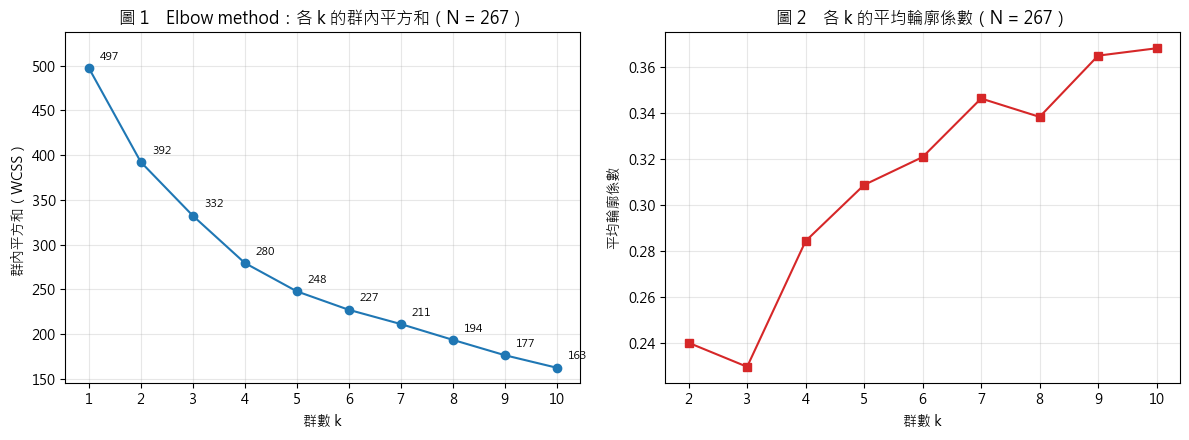

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ax = axes[0]
ax.plot(res.index, res["WCSS"], marker="o", color="#1f77b4")
for k, v in res["WCSS"].items():
    ax.annotate(f"{v:.0f}", (k, v), textcoords="offset points", xytext=(8, 6), ha="left", fontsize=8)
ax.set_ylim(top=res["WCSS"].max() * 1.08)
ax.set_title(f"圖 1　Elbow method：各 k 的群內平方和（N = {len(X)}）")
ax.set_xlabel("群數 k")
ax.set_ylabel("群內平方和（WCSS）")
ax.set_xticks(res.index)
ax.grid(alpha=.3)

ax = axes[1]
r2 = res.dropna(subset=["輪廓係數"])
ax.plot(r2.index, r2["輪廓係數"], marker="s", color="#d62728")
ax.set_title(f"圖 2　各 k 的平均輪廓係數（N = {len(X)}）")
ax.set_xlabel("群數 k")
ax.set_ylabel("平均輪廓係數")
ax.set_xticks(r2.index)
ax.grid(alpha=.3)
fig.tight_layout()
plt.show()


### Elbow 切點：平移首尾連線

為了讓「手肘」的位置不靠肉眼判斷，用平移首尾連線的方法找切點：

1. 把 k = 1 和 k = 10 兩點連成一條直線（虛線）。這條線的斜率是「k 從 1 加到 10，平均每多一群 WCSS 減少多少」。
2. 把這條線往下平行移動，直到剛好碰到 WCSS 曲線；碰到的那一點就是切點。
3. 切點等於「曲線在首尾連線下方、離連線最遠的 k」。在切點之前，每多一群 WCSS 減少的量都大於平均；在切點之後，每多一群的減少量都小於平均，也就是多分一群的效益開始低於平均。

這個切點只看相對距離，不受縱軸單位影響。


表 3b　平移首尾連線找切點（N = 267）：首尾連線斜率 = -37.20，即平均每多一群 WCSS 減少 37.20；切點 k = 4（距離 106.2）


,WCSS,首尾連線的值,連線 − WCSS（離連線距離）,比前一個 k 減少
k,,,,
1,497.38,497.38,0.00,NaN
2,392.33,460.18,67.86,105.06
3,332.39,422.98,90.59,59.94
4,279.58,385.78,106.20,52.81
5,247.90,348.58,100.68,31.68
6,227.28,311.38,84.10,20.62
7,211.36,274.18,62.82,15.92
8,193.73,236.98,43.25,17.63
9,176.58,199.78,23.20,17.15


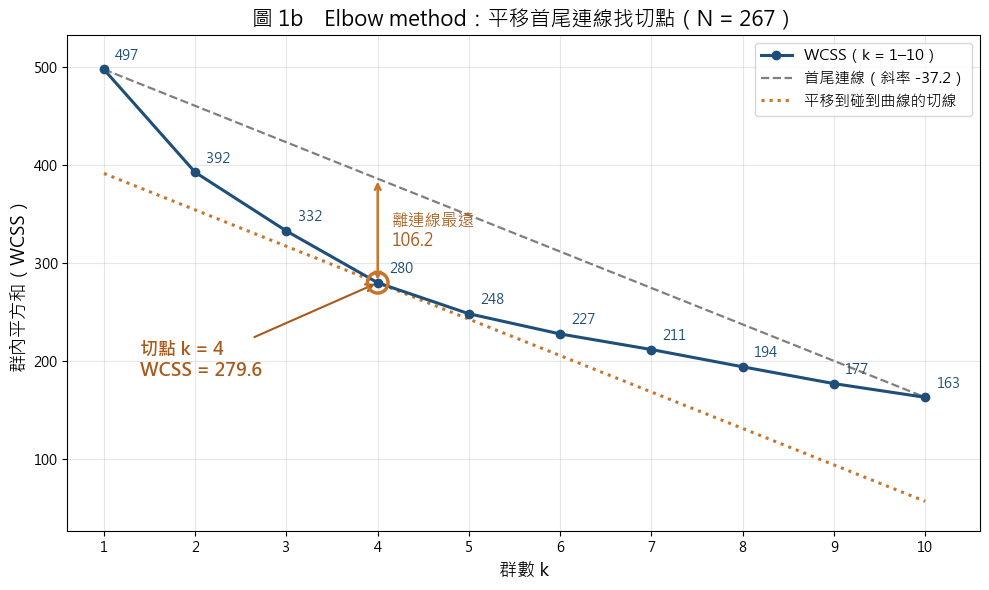

In [6]:
w = res["WCSS"]
ks = np.array(w.index, dtype=float)
slope = (w.iloc[-1] - w.iloc[0]) / (ks[-1] - ks[0])
chord = w.iloc[0] + slope * (ks - ks[0])
gap = pd.Series(chord - w.values, index=w.index)
k_star = int(gap.idxmax())
tan_tbl = pd.DataFrame({"WCSS": w, "首尾連線的值": chord, "連線 − WCSS（離連線距離）": gap,
                        "比前一個 k 減少": res["WCSS 較前一個 k 減少"]})
print(f"表 3b　平移首尾連線找切點（N = {len(X)}）：首尾連線斜率 = {slope:.2f}，"
      f"即平均每多一群 WCSS 減少 {-slope:.2f}；切點 k = {k_star}（距離 {gap.max():.1f}）")
display(tan_tbl.round(2))

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(ks, w.values, marker="o", color="#1f4e79", linewidth=2.2, label="WCSS（k = 1–10）", zorder=3)
ax.plot([ks[0], ks[-1]], [w.iloc[0], w.iloc[-1]], linestyle="--", color="#7f7f7f", linewidth=1.6,
        label=f"首尾連線（斜率 {slope:.1f}）")
shift = gap.max()
ax.plot(ks, chord - shift, linestyle=":", color="#C8742B", linewidth=2.2, label="平移到碰到曲線的切線")
yk = w.loc[k_star]
ax.annotate("", xy=(k_star, yk), xytext=(k_star, yk + shift),
            arrowprops=dict(arrowstyle="<->", color="#C8742B", linewidth=1.8))
ax.text(k_star + 0.15, yk + shift / 2, f"離連線最遠\n{shift:.1f}", color="#A85A1B", fontsize=12, va="center")
ax.scatter([k_star], [yk], s=220, facecolors="none", edgecolors="#C8742B", linewidths=2.5, zorder=4)
ax.annotate(f"切點 k = {k_star}\nWCSS = {yk:.1f}", xy=(k_star, yk), xytext=(k_star - 2.6, yk - 95),
            fontsize=13, color="#A85A1B", fontweight="bold",
            arrowprops=dict(arrowstyle="->", color="#A85A1B", linewidth=1.5))
for k, v in w.items():
    ax.annotate(f"{v:.0f}", (k, v), textcoords="offset points", xytext=(8, 7), ha="left", fontsize=10, color="#1f4e79")
ax.set_title(f"圖 1b　Elbow method：平移首尾連線找切點（N = {len(X)}）", fontsize=15)
ax.set_xlabel("群數 k", fontsize=13)
ax.set_ylabel("群內平方和（WCSS）", fontsize=13)
ax.set_xticks(ks)
ax.set_xlim(0.6, 10.6)
ax.set_ylim(min((chord - shift).min(), w.min()) - 30, w.max() * 1.07)
ax.legend(loc="upper right", fontsize=11)
ax.grid(alpha=.3)
fig.tight_layout()
asset_dir = PROJECT_ROOT / "finding" / "candidate_kmeans_elbow_assets"
asset_dir.mkdir(exist_ok=True)
fig.savefig(asset_dir / "elbow_tangent.png", dpi=200)
plt.show()


表 4　敏感度檢查：全樣本（N = 267）與排除報導／約略年齡者（N = 245）


,全樣本 WCSS,全樣本減少幅度（%）,排除報導／約略年齡 WCSS,排除後減少幅度（%）
k,,,,
1,497.38,NaN,449.29,NaN
2,392.33,21.12,352.68,21.50
3,332.39,15.28,296.53,15.92
4,279.58,15.89,247.75,16.45
5,247.90,11.33,219.00,11.60
6,227.28,8.32,198.23,9.48
7,211.36,7.00,183.77,7.30
8,193.73,8.34,168.39,8.37
9,176.58,8.85,157.17,6.67


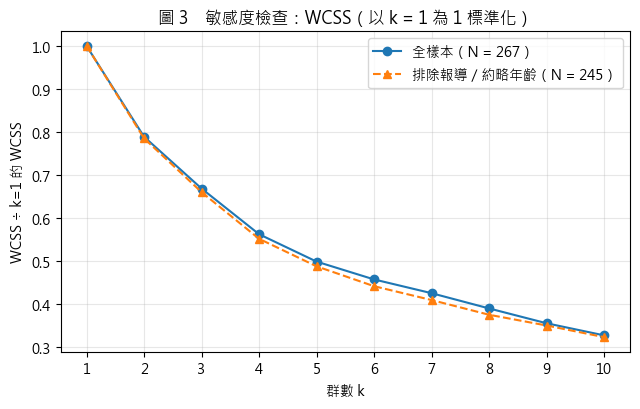

In [7]:
# 敏感度檢查：G1 年齡有部分來自報導年齡（可能差 ±1）或約略值。
# 只保留以出生日期或原既有來源計算年齡者，重跑 elbow，看 WCSS 曲線形狀是否改變。
keep = df["G1_age_basis"].isin(["birth_date", "existing_source"])
res_s = elbow(X.loc[keep].values)
cmp = pd.DataFrame({"全樣本 WCSS": res["WCSS"], "全樣本減少幅度（%）": res["減少幅度（%）"],
                    "排除報導／約略年齡 WCSS": res_s["WCSS"], "排除後減少幅度（%）": res_s["減少幅度（%）"]})
print(f"表 4　敏感度檢查：全樣本（N = {len(X)}）與排除報導／約略年齡者（N = {int(keep.sum())}）")
display(cmp.round(2))

fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(res.index, res["WCSS"] / res["WCSS"].iloc[0], marker="o", label=f"全樣本（N = {len(X)}）")
ax.plot(res_s.index, res_s["WCSS"] / res_s["WCSS"].iloc[0], marker="^", linestyle="--",
        label=f"排除報導／約略年齡（N = {int(keep.sum())}）")
ax.set_title("圖 3　敏感度檢查：WCSS（以 k = 1 為 1 標準化）")
ax.set_xlabel("群數 k")
ax.set_ylabel("WCSS ÷ k=1 的 WCSS")
ax.set_xticks(res.index)
ax.legend()
ax.grid(alpha=.3)
fig.tight_layout()
plt.show()


### 最終分群（k = 4）

許以琳於 2026-11-10 看過上方 elbow 結果後選定 **k = 4**。以下用 k = 4 重跑 k-means（50 組起點取 WCSS 最小解），群別依人數由多到少編為第 1–4 群。接著：

1. 各群特徵表：每群的人數、平均年齡（附 95% 信賴區間）與各類別比例；
2. 群別 × 公職類型、群別 × 政黨、群別 × 縣市的交叉表（公職類型與縣市不在分群變數內，用來檢查分群是否只是反映這些分類）；
3. 穩定度檢查：換 20 組不同隨機種子重跑，以及排除報導／約略年齡者重跑，比較分群結果的一致程度（調整蘭德指數 ARI，1 表示完全一致，0 表示和隨機分配差不多）。


In [8]:
K = 4
lab4, wcss4, cent4 = kmeans(X.values.astype(float), K, n_init=50, seed=RANDOM_STATE + K)
order = pd.Series(lab4).value_counts().index.tolist()          # 依人數排序
relabel = {old: new + 1 for new, old in enumerate(order)}
df["cluster"] = pd.Series(lab4).map(relabel).values
print(f"k = {K}，WCSS = {wcss4:.2f}，各群人數：", df["cluster"].value_counts().sort_index().to_dict())

def ci95(x):
    m, sd, n = x.mean(), x.std(ddof=1), len(x)
    h = 1.96 * sd / np.sqrt(n)
    return m, m - h, m + h

def describe(g):
    m, lo, hi = ci95(g["age"])
    col = {"人數": len(g), "平均年齡": m, "年齡 95% CI 下限": lo, "年齡 95% CI 上限": hi,
           "女性（%）": 100 * (g["sex"] == "女").mean()}
    for lvl in ["研究所", "大學", "大學以下"]:
        col[f"學歷：{lvl}（%）"] = 100 * (g["education"] == lvl).mean()
    for pty in ["國民黨", "民進黨", "民眾黨", "其他政黨", "無黨籍／未經政黨推薦"]:
        col[f"政黨：{pty}（%）"] = 100 * (g["party"] == pty).mean()
    col["首次參選（%）"] = 100 * (g["first_time"] == "首次參選").mean()
    col["政治家族（%）"] = 100 * (g["political_family"] == "有").mean()
    return col

prof = {f"第 {c} 群": describe(g) for c, g in df.groupby("cluster")}
prof["全樣本"] = describe(df)
profile = pd.DataFrame(prof)
print(f"表 5　k = 4 各群特徵（N = {len(df)}；百分比分母為該群人數）")
display(profile.round(1))


k = 4，WCSS = 279.58，各群人數： {1: 70, 2: 68, 3: 65, 4: 64}
表 5　k = 4 各群特徵（N = 267；百分比分母為該群人數）


,第 1 群,第 2 群,第 3 群,第 4 群,全樣本
人數,70.0,68.0,65.0,64.0,267.0
平均年齡,49.3,54.2,55.1,49.5,52.0
年齡 95% CI 下限,46.4,51.7,52.0,47.1,50.6
年齡 95% CI 上限,52.2,56.6,58.2,52.0,53.4
女性（%）,34.3,44.1,26.2,45.3,37.5
學歷：研究所（%）,0.0,91.2,69.2,96.9,63.3
學歷：大學（%）,100.0,0.0,0.0,0.0,26.2
學歷：大學以下（%）,0.0,8.8,30.8,3.1,10.5
政黨：國民黨（%）,24.3,100.0,0.0,0.0,31.8
政黨：民進黨（%）,24.3,0.0,0.0,98.4,30.0


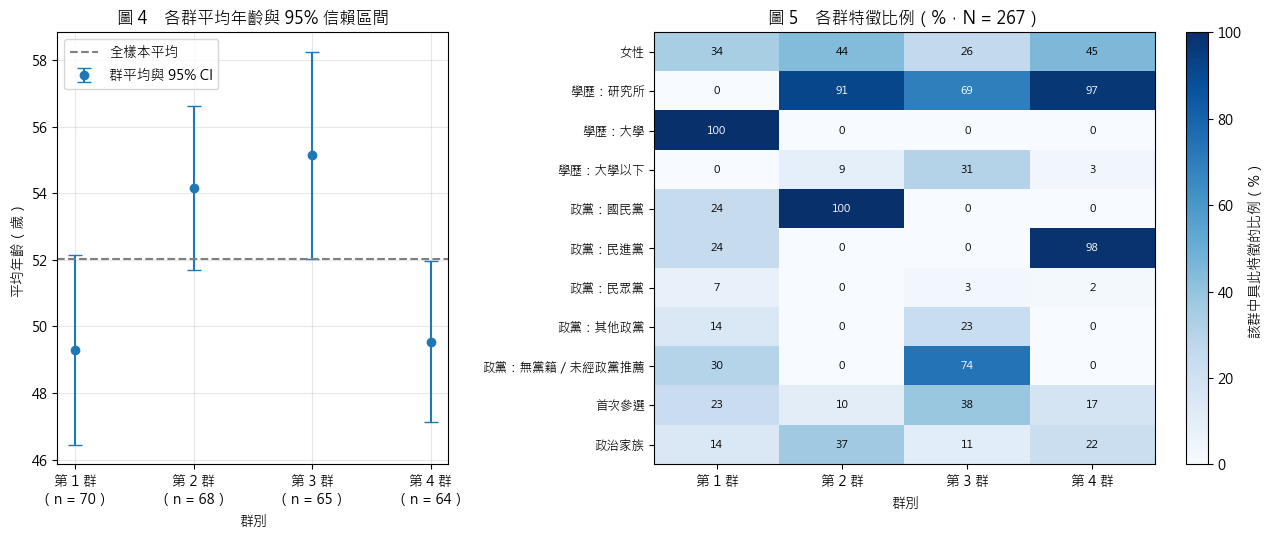

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [1, 1.6]})
ax = axes[0]
cl = [c for c in profile.columns if c != "全樣本"]
m = profile.loc["平均年齡", cl].astype(float)
lo = profile.loc["年齡 95% CI 下限", cl].astype(float)
hi = profile.loc["年齡 95% CI 上限", cl].astype(float)
ax.errorbar(range(len(cl)), m, yerr=[m - lo, hi - m], fmt="o", capsize=5, color="#1f77b4", label="群平均與 95% CI")
ax.axhline(profile.loc["平均年齡", "全樣本"], color="gray", linestyle="--", label="全樣本平均")
ax.set_xticks(range(len(cl)))
ax.set_xticklabels([f"{c}\n（n = {int(profile.loc['人數', c])}）" for c in cl])
ax.set_title("圖 4　各群平均年齡與 95% 信賴區間")
ax.set_xlabel("群別")
ax.set_ylabel("平均年齡（歲）")
ax.legend(loc="best")
ax.grid(alpha=.3)

ax = axes[1]
rows = [r for r in profile.index if r.endswith("（%）")]
H = profile.loc[rows, cl].astype(float)
im = ax.imshow(H.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(cl)))
ax.set_xticklabels(cl)
ax.set_yticks(range(len(rows)))
ax.set_yticklabels([r.replace("（%）", "") for r in rows], fontsize=9)
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        v = H.values[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > 60 else "black")
ax.set_title(f"圖 5　各群特徵比例（%，N = {len(df)}）")
ax.set_xlabel("群別")
fig.colorbar(im, ax=ax, label="該群中具此特徵的比例（%）")
fig.tight_layout()
plt.show()


In [10]:
def xtab(var, title):
    rowlab = df["cluster"].map(lambda c: f"第 {c} 群")
    t = pd.crosstab(rowlab, df[var], margins=True, margins_name="合計")
    pct = pd.crosstab(rowlab, df[var], normalize="index") * 100
    print(f"{title}（N = {len(df)}；第一個表為人數，第二個表為列百分比）")
    display(t)
    display(pct.round(1))

df["city_group"] = np.where(df["office_type"] == "直轄市議員", df["county_city"] + "議員", "首長")
xtab("office_type", "表 6　群別 × 公職類型")
xtab("party", "表 7　群別 × 政黨")
xtab("city_group", "表 8　群別 × 縣市（議員分臺北、高雄；首長合併一欄）")


表 6　群別 × 公職類型（N = 267；第一個表為人數，第二個表為列百分比）


office_type,直轄市議員,直轄市長,縣（市）長,合計
cluster,,,,
第 1 群,48,6,16,70
第 2 群,52,6,10,68
第 3 群,39,5,21,65
第 4 群,48,6,10,64
合計,187,23,57,267


office_type,直轄市議員,直轄市長,縣（市）長
cluster,,,
第 1 群,68.6,8.6,22.9
第 2 群,76.5,8.8,14.7
第 3 群,60.0,7.7,32.3
第 4 群,75.0,9.4,15.6


表 7　群別 × 政黨（N = 267；第一個表為人數，第二個表為列百分比）


party,其他政黨,國民黨,民眾黨,民進黨,無黨籍／未經政黨推薦,合計
cluster,,,,,,
第 1 群,10,17,5,17,21,70
第 2 群,0,68,0,0,0,68
第 3 群,15,0,2,0,48,65
第 4 群,0,0,1,63,0,64
合計,25,85,8,80,69,267


party,其他政黨,國民黨,民眾黨,民進黨,無黨籍／未經政黨推薦
cluster,,,,,
第 1 群,14.3,24.3,7.1,24.3,30.0
第 2 群,0.0,100.0,0.0,0.0,0.0
第 3 群,23.1,0.0,3.1,0.0,73.8
第 4 群,0.0,0.0,1.6,98.4,0.0


表 8　群別 × 縣市（議員分臺北、高雄；首長合併一欄）（N = 267；第一個表為人數，第二個表為列百分比）


city_group,臺北市議員,首長,高雄市議員,合計
cluster,,,,
第 1 群,27,22,21,70
第 2 群,25,16,27,68
第 3 群,20,26,19,65
第 4 群,18,16,30,64
合計,90,80,97,267


city_group,臺北市議員,首長,高雄市議員
cluster,,,
第 1 群,38.6,31.4,30.0
第 2 群,36.8,23.5,39.7
第 3 群,30.8,40.0,29.2
第 4 群,28.1,25.0,46.9


In [11]:
from math import comb

def ari(a, b):
    ct = pd.crosstab(pd.Series(a), pd.Series(b)).values
    sum_ij = sum(comb(int(n), 2) for n in ct.ravel())
    sum_a = sum(comb(int(n), 2) for n in ct.sum(1))
    sum_b = sum(comb(int(n), 2) for n in ct.sum(0))
    tot = comb(int(ct.sum()), 2)
    exp = sum_a * sum_b / tot
    mx = (sum_a + sum_b) / 2
    return (sum_ij - exp) / (mx - exp)

aris, wc = [], []
for sd in [RANDOM_STATE + 1000 + i for i in range(20)]:
    l, w, _ = kmeans(X.values.astype(float), K, n_init=50, seed=sd)
    aris.append(ari(df["cluster"].values, l))
    wc.append(w)
aris = np.array(aris)
print(f"表 9　穩定度：換 20 組隨機種子重跑 k = 4，ARI 平均 {aris.mean():.3f}、最小 {aris.min():.3f}，"
      f"完全一致（ARI = 1）{int((aris > 0.9999).sum())}／20 次；WCSS 範圍 {min(wc):.2f}–{max(wc):.2f}（主結果 {wcss4:.2f}）")

keep_idx = np.where(keep.values)[0]
l_s, _, _ = kmeans(X.values[keep_idx].astype(float), K, n_init=50, seed=RANDOM_STATE + K)
print(f"排除報導／約略年齡者（N = {len(keep_idx)}）重跑 k = 4，與主結果在這 {len(keep_idx)} 人上的 ARI = "
      f"{ari(df['cluster'].values[keep_idx], l_s):.3f}")


表 9　穩定度：換 20 組隨機種子重跑 k = 4，ARI 平均 0.993、最小 0.866，完全一致（ARI = 1）19／20 次；WCSS 範圍 279.58–280.72（主結果 279.58）
排除報導／約略年齡者（N = 245）重跑 k = 4，與主結果在這 245 人上的 ARI = 0.914


In [12]:
# 輸出各候選人的群別，供後續策略比較使用（本 finding 的結果檔）
out_dir = PROJECT_ROOT / "finding" / "candidate_kmeans_elbow_assets"
out_dir.mkdir(exist_ok=True)
out_path = out_dir / "cluster_labels_k4.csv"
lab_out = df[["candidate_key", "candidate_name", "office_type", "county_city", "cluster"]]
lab_out.to_csv(out_path, index=False, encoding="utf-8-sig")
chk = pd.read_csv(out_path, dtype=str, encoding="utf-8-sig")
assert len(chk) == len(df) and chk["candidate_key"].is_unique
assert (chk["cluster"].astype(int).values == df["cluster"].values).all()
print("已存：", out_path.relative_to(PROJECT_ROOT).as_posix(), "；", len(chk), "列；SHA-256 =",
      hashlib.sha256(out_path.read_bytes()).hexdigest())


已存： finding/candidate_kmeans_elbow_assets/cluster_labels_k4.csv ； 267 列；SHA-256 = aad8958d10d0bbcf8434d588a94aa301a2c02a3b2131cdcbf10733f1b31f9f84


### 結果說明

**樣本。** 267 位候選人（直轄市長 23、縣（市）長 57、臺北與高雄市議員 187），G1–G6 皆無缺值，沒有排除任何人。特徵矩陣共 12 欄。

**Elbow（圖 1、表 3）。** WCSS 從 k = 1 的 497.4 降到 k = 10 的 162.6。各 k 較前一個 k 的減少幅度：k = 2 為 21.1%，k = 3 為 15.3%，k = 4 為 15.9%，k = 5 為 11.3%；從 k = 6 起每多一群只再減少 7–9%。曲線在 k = 4 到 5 之間明顯轉緩。以平移首尾連線找切點（圖 1b、表 3b）：首尾連線斜率 −37.2（平均每多一群減少 37.2），曲線在 k = 4 離連線最遠（106.2），切點為 **k = 4**；k = 2–4 每多一群的減少量（105.1、59.9、52.8）都高於平均，k = 5 起（31.7、20.6……）都低於平均。輪廓係數（圖 2）介於 0.23 到 0.37，隨 k 大致上升、沒有明確高峰，所以只作參考。排除年齡來自報導或約略值的 22 人後（表 4、圖 3），曲線幾乎重疊，手肘位置不變。許以琳據此選定 **k = 4**（每群至少 64 人，後續比較較穩定）。

**k = 4 的四群（表 5、圖 4–5）。** 四群人數相近（70、68、65、64）。

| 群別 | 人數 | 主要特徵 |
| --- | --- | --- |
| 第 1 群 | 70 | 全部為大學學歷；政黨混合（無黨籍 30%、國民黨 24%、民進黨 24%、其他 14%、民眾黨 7%）；平均 49.3 歲；政治家族 14% |
| 第 2 群 | 68 | 全部為國民黨；研究所 91%；平均 54.2 歲；政治家族 37%（四群最高）；首次參選 10%（最低） |
| 第 3 群 | 65 | 無黨籍 74%、其他政黨 23%；大學以下 31%（最高）；平均 55.1 歲（最高）；首次參選 38%（最高）；女性 26%（最低） |
| 第 4 群 | 64 | 民進黨 98%；研究所 97%；平均 49.5 歲；女性 45%；政治家族 22% |

年齡方面，第 2、3 群平均 54–55 歲，第 1、4 群約 49 歲，兩組的 95% 信賴區間只在 52 歲附近些微重疊（圖 4），差距約 5 歲。

**交叉表（表 6–8）。** 各群中議員約占 60–77%，首長與議員在四群間的分布差異不大；第 3 群的縣（市）長比例較高（32%），反映縣市長選舉中無黨籍參選人較多。臺北與高雄議員也分散在各群，第 4 群（民進黨）高雄議員較多（47%）。公職類型與縣市都不在分群變數內，這些交叉表顯示分群主要不是在分首長或縣市。

**穩定度（表 9）。** 換 20 組隨機種子重跑 k = 4，有 19 次與主結果完全相同（ARI 平均 0.993，最低 0.866），WCSS 介於 279.58–280.72。排除年齡來自報導或約略值的 22 人後重跑，與主結果的 ARI 為 0.914。分群結果穩定。

**解讀與限制。** 這組分群的核心是政黨與學歷：國民黨、民進黨、無黨籍／小黨各成一群，剩下的一群是所有大學學歷者。原因是這兩個變數拆成多個虛擬變數，在距離中的比重高於年齡、性別等單一欄位。因此「各群策略不同」時，很難區分是背景類型的差異還是政黨差異；proposal 也提醒過分群可能和黨派高度重疊。可行的檢查：(1) 不放政黨重跑，政黨改用交叉表呈現；(2) 用 proposal 原規劃的 Gower 距離＋PAM 比較結果。k-means 以 numpy 實作（k-means++ 起點、50 組起點取最佳），因為本機的應用程式控制原則封鎖了 scikit-learn。

**輸出。** 每位候選人的群別存於 `finding/candidate_kmeans_elbow_assets/cluster_labels_k4.csv`（267 列），供後續各群策略指標比較使用。

<!-- Completion: run all cells in order from a clean kernel and save the actual
outputs in this ipynb. Inspect the notebook's code, tables, and figures for
readable labels, nonoverlapping text, and agreement with the takeaways. Deliver
the executed ipynb directly and record its actual execution status. Produce HTML
only when separately requested, never as a default export or a condition of completion. -->
